In [22]:
import pandas as pd

print("Jupyter is working!")
print("Pandas version:", pd.__version__)

Jupyter is working!
Pandas version: 2.3.3


In [23]:
from pathlib import Path

file_path = Path("../data/raw/online_retail_II.xlsx")

print("Dataset found:", file_path.exists())

Dataset found: True


In [24]:
excel_file = pd.ExcelFile(file_path)

print("Available worksheets:")
print(excel_file.sheet_names)

Available worksheets:
['Year 2009-2010', 'Year 2010-2011']


In [25]:
df = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 525461
Columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [26]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Total cells:", df.size)

Number of rows: 525461
Number of columns: 8
Total cells: 4203688


In [27]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [29]:
missing_values = df.isna().sum()

missing_percentage = (
    df.isna().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing (%)": missing_percentage
})

missing_summary

,Missing Values,Missing (%)
Invoice,0,0.00
StockCode,0,0.00
Description,2928,0.56
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,107927,20.54
Country,0,0.00


In [30]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

Duplicate rows: 6865
Duplicate percentage: 1.31 %


In [31]:
quantity_summary = pd.DataFrame({
    "Transaction Type": [
        "Positive quantity",
        "Negative quantity",
        "Zero quantity"
    ],
    "Number of Rows": [
        (df["Quantity"] > 0).sum(),
        (df["Quantity"] < 0).sum(),
        (df["Quantity"] == 0).sum()
    ]
})

quantity_summary

,Transaction Type,Number of Rows
0,Positive quantity,513135
1,Negative quantity,12326
2,Zero quantity,0


In [32]:
cancelled_mask = (
    df["Invoice"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

print("Cancelled invoice lines:", cancelled_mask.sum())

print(
    "Distinct cancelled invoices:",
    df.loc[cancelled_mask, "Invoice"].nunique()
)

Cancelled invoice lines: 10206
Distinct cancelled invoices: 4592


In [33]:
transaction_checks = pd.DataFrame({
    "Check": [
        "Negative quantity with C invoice",
        "Negative quantity without C invoice",
        "Positive quantity with C invoice"
    ],
    "Rows": [
        ((df["Quantity"] < 0) & cancelled_mask).sum(),
        ((df["Quantity"] < 0) & ~cancelled_mask).sum(),
        ((df["Quantity"] > 0) & cancelled_mask).sum()
    ]
})

transaction_checks

,Check,Rows
0,Negative quantity with C invoice,10205
1,Negative quantity without C invoice,2121
2,Positive quantity with C invoice,1


In [34]:
df["Price"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 1]
)

count    525461.000000
mean          4.688834
std         146.126914
min      -53594.360000
25%           1.250000
50%           2.100000
75%           4.210000
95%          10.170000
99%          19.950000
100%      25111.090000
max       25111.090000
Name: Price, dtype: float64

In [35]:
df.nlargest(10, "Price")[
    ["Invoice", "StockCode", "Description", "Quantity", "Price"]
]

,Invoice,StockCode,Description,Quantity,Price
241824,C512770,M,Manual,-1,25111.09
241827,512771,M,Manual,1,25111.09
320581,C520667,BANK CHARGES,Bank Charges,-1,18910.69
517953,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33
517955,537632,AMAZONFEE,AMAZON FEE,1,13541.33
519294,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33
519170,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79
135012,C502262,M,Manual,-1,10953.50
135013,502263,M,Manual,1,10953.50
135014,C502264,M,Manual,-1,10953.50


In [36]:
quantity_summary

,Transaction Type,Number of Rows
0,Positive quantity,513135
1,Negative quantity,12326
2,Zero quantity,0


In [37]:
transaction_checks

,Check,Rows
0,Negative quantity with C invoice,10205
1,Negative quantity without C invoice,2121
2,Positive quantity with C invoice,1


In [38]:
price_summary

count    525461.000000
mean          4.688834
std         146.126914
min      -53594.360000
25%           1.250000
50%           2.100000
75%           4.210000
max       25111.090000
Name: Price, dtype: float64

In [39]:
df["Price"].isna().sum()

np.int64(0)

In [40]:
print("Total rows:", len(df))
print("Non-null prices:", df["Price"].count())
print("Missing prices:", df["Price"].isna().sum())
print("Zero prices:", (df["Price"] == 0).sum())
print("Negative prices:", (df["Price"] < 0).sum())

Total rows: 525461
Non-null prices: 525461
Missing prices: 0
Zero prices: 3687
Negative prices: 3


In [41]:
df["Price"].describe()

count    525461.000000
mean          4.688834
std         146.126914
min      -53594.360000
25%           1.250000
50%           2.100000
75%           4.210000
max       25111.090000
Name: Price, dtype: float64

### Price Data Quality — Initial Observation

My initial check found no missing values in the Price column of the 2009–2010 dataset.

However, this doesn't necessarily mean all prices are correct. I still need to investigate zero, negative, and unusually high prices to understand whether they represent valid transactions, adjustments, or possible data quality issues.

I'll review these records before deciding how they should be handled in the revenue analysis.

### Price Data Quality — Initial Observation

My initial check found no missing values in the Price column of the 2009–2010 dataset.

However, this doesn't necessarily mean all prices are correct. I still need to investigate zero, negative, and unusually high prices to understand whether they represent valid transactions, adjustments, or possible data quality issues.

I'll review these records before deciding how they should be handled in the revenue analysis.

In [42]:
#####Investigate the 3 negative prices

negative_prices = df[df["Price"] < 0]

negative_prices[
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Customer ID",
        "Country"
    ]
]

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,-38925.87,NaN,United Kingdom


In [43]:
###### Investigate the 3,687 zero-price records
zero_prices = df[df["Price"] == 0]

zero_prices[
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price"
    ]
].head(20)

,Invoice,StockCode,Description,Quantity,Price
263,489464,21733,85123a mixed,-96,0.0
283,489463,71477,short,-240,0.0
284,489467,85123A,21733 mixed,-192,0.0
470,489521,21646,NaN,-50,0.0
3114,489655,20683,NaN,-44,0.0
3161,489659,21350,NaN,230,0.0
3162,489660,35956,lost,-1043,0.0
3168,489663,35605A,damages,-117,0.0
3731,489781,84292,NaN,17,0.0
4296,489806,18010,NaN,-770,0.0


In [44]:
####### identify the most common descriptions among these records:
zero_prices["Description"].value_counts(
    dropna=False
).head(15)

Description
NaN                                    2928
?                                        45
damages                                  39
damaged                                  38
missing                                  24
checked                                   8
OWL DOORSTOP                              8
POLYESTER FILLER PAD 45x45cm              7
PICNIC BASKET WICKER LARGE                7
dotcom                                    6
AIRLINE BAG VINTAGE WORLD CHAMPION        6
HEART OF WICKER SMALL                     6
FLAG OF ST GEORGE CAR FLAG                6
given away                                6
smashed                                   5
Name: count, dtype: int64

In [45]:
#####Check whether zero-price records have negative quantities

pd.DataFrame({
    "Quantity Category": [
        "Positive",
        "Negative",
        "Zero"
    ],
    "Rows": [
        (zero_prices["Quantity"] > 0).sum(),
        (zero_prices["Quantity"] < 0).sum(),
        (zero_prices["Quantity"] == 0).sum()
    ]
})

,Quantity Category,Rows
0,Positive,1566
1,Negative,2121
2,Zero,0


#### Documenting my findings

### Price Quality Assessment

I found no missing values in the Price column. However, 3,687 records have a price of zero, and 3 records have negative prices.

This shows that having complete data doesn't necessarily mean the data is suitable for analysis.

Before calculating revenue, I'll investigate these records to understand whether they represent valid transactions, adjustments, or errors. I won't remove them until I have enough evidence to justify that decision.

In [46]:
####Check the remaining zero-price records

print("Positive quantities:", (zero_prices["Quantity"] > 0).sum())
print("Negative quantities:", (zero_prices["Quantity"] < 0).sum())
print("Zero quantities:", (zero_prices["Quantity"] == 0).sum())

Positive quantities: 1566
Negative quantities: 2121
Zero quantities: 0


In [47]:
##### Investigate the negative-quantity records

zero_prices.loc[
    zero_prices["Quantity"] < 0,
    ["Invoice", "StockCode", "Description", "Quantity", "Price"]
].head(20)

,Invoice,StockCode,Description,Quantity,Price
263,489464,21733,85123a mixed,-96,0.0
283,489463,71477,short,-240,0.0
284,489467,85123A,21733 mixed,-192,0.0
470,489521,21646,NaN,-50,0.0
3114,489655,20683,NaN,-44,0.0
3162,489660,35956,lost,-1043,0.0
3168,489663,35605A,damages,-117,0.0
4296,489806,18010,NaN,-770,0.0
4538,489820,21133,invcd as 84879?,-720,0.0
4566,489821,85049G,NaN,-240,0.0


In [48]:
##### Check whether these records are cancellations

zero_prices_negative = zero_prices[
    zero_prices["Quantity"] < 0
].copy()

zero_prices_negative["IsCancellation"] = (
    zero_prices_negative["Invoice"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

zero_prices_negative["IsCancellation"].value_counts()

IsCancellation
False    2121
Name: count, dtype: Int64

### Zero-Price Transaction Investigation

I identified 3,687 records with zero prices. Of these, 2,121 have negative quantities, 1,566 have positive quantities, and none have zero quantities.

The negative-quantity records may represent stock adjustments, corrections, or other non-standard transactions. Because their prices are zero, they have no direct effect on calculated revenue.

I'll investigate their invoice numbers and descriptions before deciding how to classify them.

0 are marked as cancellations 
All 2,121 records have invoice numbers that do not begin with C.

In [49]:
#### Investigate their descriptions

zero_prices_negative["Description"].value_counts(
    dropna=False
).head(20)

Description
NaN            1827
?                42
damages          39
damaged          36
missing          24
dotcom            6
given away        6
checked           5
smashed           5
Damages           4
crushed           4
ebay sales        4
MIA               4
No Stock          3
check             3
Damaged           3
counted           3
gone              2
discoloured       2
broken zips       2
Name: count, dtype: int64

In [50]:
##### Examine their stock codes
zero_prices_negative["StockCode"].value_counts(
    dropna=False
).head(20)



StockCode
22423     9
46000M    5
20852     5
84016     5
71477     4
21768     4
72529W    3
21298     3
21303     3
84909A    3
84559D    3
47598     3
82607E    3
21614     3
84653     3
84934     3
21493     3
21760     3
21489     3
21490     3
Name: count, dtype: int64

In [51]:
###Inspect some actual records
zero_prices_negative[
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "InvoiceDate"
    ]
].head(20)

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate
263,489464,21733,85123a mixed,-96,0.0,2009-12-01 10:52:00
283,489463,71477,short,-240,0.0,2009-12-01 10:52:00
284,489467,85123A,21733 mixed,-192,0.0,2009-12-01 10:53:00
470,489521,21646,NaN,-50,0.0,2009-12-01 11:44:00
3114,489655,20683,NaN,-44,0.0,2009-12-01 17:26:00
3162,489660,35956,lost,-1043,0.0,2009-12-01 17:43:00
3168,489663,35605A,damages,-117,0.0,2009-12-01 18:02:00
4296,489806,18010,NaN,-770,0.0,2009-12-02 12:42:00
4538,489820,21133,invcd as 84879?,-720,0.0,2009-12-02 13:23:00
4566,489821,85049G,NaN,-240,0.0,2009-12-02 13:25:00


### Negative Quantities with Zero Prices

I identified 2,121 records with negative quantities and zero prices. None of these records have invoice numbers beginning with C, which is the dataset's cancellation indicator.

This suggests that negative quantities are not always associated with explicitly cancelled invoices.

These records have no direct impact on calculated revenue because their unit prices are zero. However, they could affect quantity-based analysis.

I'll keep them in the raw dataset and investigate their descriptions and stock codes before deciding how to classify them.

In [52]:
#### sharing the output of:

zero_prices_negative["Description"].value_counts(
    dropna=False
).head(20)

Description
NaN            1827
?                42
damages          39
damaged          36
missing          24
dotcom            6
given away        6
checked           5
smashed           5
Damages           4
crushed           4
ebay sales        4
MIA               4
No Stock          3
check             3
Damaged           3
counted           3
gone              2
discoloured       2
broken zips       2
Name: count, dtype: int64

Understanding your results

Description	   Records	Possible explanation
  NaN	        1,827	 No description recorded
   ?	          42	 Unspecified adjustment
damages	          39	 Damaged inventory
damaged           36	 Damaged inventory
missing	          24	 Missing stock
given away	      6	     Stock given away
smashed	          5	     Damaged inventory
crushed	          4	     Damaged inventory
ebay sales	      4	     Possible external-channel activity
No Stock	      3	     Stock discrepancy

In [53]:
#### Let's create our first transaction classification

import numpy as np

df_checks = df.copy()

df_checks["TransactionCategory"] = "Other / Review"

cancelled_mask = (
    df_checks["Invoice"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

df_checks.loc[
    (df_checks["Quantity"] > 0)
    & (df_checks["Price"] > 0)
    & ~cancelled_mask,
    "TransactionCategory"
] = "Positive-price sale"

df_checks.loc[
    cancelled_mask,
    "TransactionCategory"
] = "Marked cancellation"

df_checks.loc[
    (df_checks["Quantity"] < 0)
    & (df_checks["Price"] == 0)
    & ~cancelled_mask,
    "TransactionCategory"
] = "Zero-price negative adjustment"

df_checks["TransactionCategory"].value_counts()

TransactionCategory
Positive-price sale               511565
Marked cancellation                10206
Zero-price negative adjustment      2121
Other / Review                      1569
Name: count, dtype: int64

### Investigation of Zero-Price Negative Quantities

I found 2,121 records with negative quantities and zero prices. None were marked as cancellations.

Of these, 1,827 (85.8%) had missing descriptions. The remaining records included descriptions such as "damages", "missing", "given away", and "crushed".

These findings suggest that some records relate to inventory adjustments rather than customer purchases or returns. However, the high number of missing descriptions prevents me from confirming the purpose of every transaction.

For the revenue analysis, I'll flag these records separately and exclude them from the preliminary sales dataset while preserving them in the original data.

In [54]:
#### investigating the three negative prices

df.loc[
    df["Price"] < 0,
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Country"
    ]
]

,Invoice,StockCode,Description,Quantity,Price,Country
179403,A506401,B,Adjust bad debt,1,-53594.36,United Kingdom
276274,A516228,B,Adjust bad debt,1,-44031.79,United Kingdom
403472,A528059,B,Adjust bad debt,1,-38925.87,United Kingdom


A bad debt adjustment generally relates to money a business does not expect to recover from a customer.

Combined bad debt adjustments −£136,552.02 Three records, each with a quantity of 1

This is important because including these records in merchandise sales would reduce your reported sales total by £136,552.02, even though they do not represent products being sold or returned.

2. What to do next with these records?
   
For the Retail Revenue Growth Analysis, I will suggest:
- Keep all three records in the raw dataset.
- Classify them separately as Bad debt adjustment.
- Exclude them from merchandise sales revenue.
- Report their combined value separately in your data quality findings.
  
As the adjustments may be relevant to a broader financial analysis, but we shouldn't mix them with product sales.

In [55]:
####Update your transaction classification
#### note: we are classifying the records, not deleting them

bad_debt_mask = (
    df_checks["StockCode"].astype("string").eq("B")
    & df_checks["Description"]
        .astype("string")
        .str.contains("Adjust bad debt", case=False, na=False)
)

df_checks.loc[
    bad_debt_mask,
    "TransactionCategory"
] = "Bad debt adjustment"

df_checks["TransactionCategory"].value_counts()

TransactionCategory
Positive-price sale               511565
Marked cancellation                10206
Zero-price negative adjustment      2121
Other / Review                      1566
Bad debt adjustment                    3
Name: count, dtype: int64

In [56]:
####Now verify the total
bad_debt_total = (
    df_checks.loc[bad_debt_mask, "Quantity"]
    * df_checks.loc[bad_debt_mask, "Price"]
).sum()

print("Bad debt records:", bad_debt_mask.sum())
print(f"Total bad debt adjustments: £{bad_debt_total:,.2f}")

Bad debt records: 3
Total bad debt adjustments: £-136,552.02


### Negative Price Investigation

I identified three records with negative prices in the 2009–2010 worksheet.

All three have the description "Adjust bad debt" and stock code "B". Their combined value is −£136,552.02.

These records appear to represent accounting adjustments rather than merchandise transactions.

I've decided to classify them separately and exclude them from merchandise sales revenue while retaining them in the original dataset. This will help prevent financial adjustments from distorting the sales analysis.

In [57]:
#### investigate the 1,566 positive-quantity, zero-price records

zero_positive = df.loc[
    (df["Price"] == 0) &
    (df["Quantity"] > 0)
]

print("Number of records:", len(zero_positive))

zero_positive["Description"].value_counts(
    dropna=False
).head(20)

Number of records: 1566


Description
NaN                                    1101
OWL DOORSTOP                              8
POLYESTER FILLER PAD 45x45cm              7
PICNIC BASKET WICKER LARGE                7
AIRLINE BAG VINTAGE WORLD CHAMPION        6
FLAG OF ST GEORGE CAR FLAG                6
HEART OF WICKER SMALL                     6
PICNIC BASKET WICKER SMALL                5
SMALL POPCORN HOLDER                      5
IVORY KITCHEN SCALES                      5
WATERING CAN BLUE ELEPHANT                5
POLYESTER FILLER PAD 40x40cm              5
ENAMEL WASH BOWL CREAM                    5
ENAMEL FIRE BUCKET CREAM                  5
ENAMEL FLOWER JUG CREAM                   4
MILK PAN PINK RETROSPOT                   4
DOOR MAT UNION JACK GUNS AND ROSES        4
AIRLINE BAG VINTAGE TOKYO 78              4
HANGING METAL STAR LANTERN                4
BOX OF 24 COCKTAIL PARASOLS               4
Name: count, dtype: int64

The results reveal another important data quality issue in the Online Retail II (2009–2010) 

dataset: some records show products being added with positive quantities but no recorded price.

Unlike the negative-quantity adjustments we investigated earlier, these records include recognisable retail products.

1. What have we discovered?
   
Positive-quantity, zero-price records
1,566

Missing descriptions
1,101
70.3% of records

The 465 records with descriptions include products such as OWL DOORSTOP, PICNIC BASKET WICKER LARGE, and IVORY KITCHEN SCALES.

These could be complimentary products, samples, promotional transactions, or records with missing price information. We cannot determine which explanation is correct from the descriptions alone.

2. Our provisional cleaning decision
Record type	                                        Treatment

Zero price, positive quantity, missing description	Flag for review
Zero price, positive quantity, valid description	Flag as possible free item or pricing issue
All 1,566 records	                                Preserve in raw data
Merchandise revenue analysis	                    Exclude from positive-price sales calculations

An important distinction: excluding these records from revenue calculations does not mean they have no business significance. 

They may still affect product quantities, inventory movements and customer behaviour.

In [58]:
##### Let's check whether the 1,566 records have customer identifiers.

customer_check = pd.DataFrame({
    "Customer ID Status": [
        "Customer ID present",
        "Customer ID missing"
    ],
    "Records": [
        zero_positive["Customer ID"].notna().sum(),
        zero_positive["Customer ID"].isna().sum()
    ]
})

customer_check

,Customer ID Status,Records
0,Customer ID present,31
1,Customer ID missing,1535


In [59]:
##### Check the invoice patterns

zero_positive = zero_positive.copy()

zero_positive["InvoicePrefix"] = (
    zero_positive["Invoice"]
    .astype("string")
    .str.extract(r"^([A-Za-z]+)", expand=False)
    .fillna("No letter prefix")
)

zero_positive["InvoicePrefix"].value_counts(
    dropna=False
)

InvoicePrefix
No letter prefix    1566
Name: count, dtype: Int64

### Positive Quantities with Zero Prices

I identified 1,566 records with positive quantities and zero prices. Of these, 1,101 (70.3%) have missing product descriptions.

The remaining 465 records include recognisable retail products, such as doorstops, picnic baskets, and kitchen scales.

These records could represent complimentary items, promotional transactions, or pricing issues, but the available information does not confirm their purpose.

For now, I'll preserve them in the raw dataset and flag them for further investigation. They won't contribute to the preliminary positive-price sales revenue calculation, but they may still be relevant to inventory and customer analysis.

We've just investigated all 3,690 non-positive-price records.

Finding	Records
Negative-quantity, zero-price	2,121
Positive-quantity, zero-price	1,566
Negative-price bad debt adjustments	3

Total	3,690

The next objective is to finish the transaction classification, then investigate cancellations and returns before creating a clean sales dataset.

In Online Retail II, invoice numbers beginning with C indicate cancellations. None of these 1,566 records follow that pattern.

However, this does not prove that they are completed sales. 

They could still represent complimentary items, stock movements or pricing errors.

Here's what we've established:

Finding                                                    	Result

Positive-quantity, zero-price records                   	        1,566
Missing product descriptions	                            1,101 (70.3%)
Records with descriptions	                                  465 (29.7%)
Records with no invoice letter prefix	                     1,566 (100%)
Records marked as cancellations	                                        0

In [60]:
#### Checking customer IDs. So, before deciding how to classify these records, 
#### let's investigate whether they are linked to identifiable customers.

customer_check = pd.DataFrame({
    "Customer ID Status": [
        "Customer ID present",
        "Customer ID missing"
    ],
    "Records": [
        zero_positive["Customer ID"].notna().sum(),
        zero_positive["Customer ID"].isna().sum()
    ]
})

customer_check

,Customer ID Status,Records
0,Customer ID present,31
1,Customer ID missing,1535


In [61]:
##### A customer ID may provide evidence that the record belongs to a customer transaction. 
#### Missing customer IDs make it harder to determine the transaction's purpose.
### We should also check whether these records have normal-looking invoice numbers:

zero_positive[
    ["Invoice", "StockCode", "Description",
     "Quantity", "Price", "Customer ID"]
].head(15)

,Invoice,StockCode,Description,Quantity,Price,Customer ID
3161,489659,21350,NaN,230,0.0,NaN
3731,489781,84292,NaN,17,0.0,NaN
4674,489825,22076,6 RIBBONS EMPIRE,12,0.0,16126.0
5904,489861,DOT,DOTCOM POSTAGE,1,0.0,NaN
6378,489882,35751C,NaN,12,0.0,NaN
6555,489898,79323G,NaN,954,0.0,NaN
6581,489903,21166,NaN,48,0.0,NaN
6781,489998,48185,DOOR MAT FAIRY CAKE,2,0.0,15658.0
7204,490015,21982,NaN,467,0.0,NaN
9249,490123,84508B,NaN,184,0.0,NaN


### Invoice Pattern Investigation

I checked the invoice numbers for the 1,566 records with positive quantities and zero prices.

None of these invoices begin with a letter, meaning they are not identified by the dataset's cancellation prefix.

However, this does not confirm that they represent completed sales. Further investigation is needed to determine whether they are complimentary items, inventory movements or pricing errors.

I'll examine customer identifiers before making a final classification decision.

This is still useful because it reveals something important about your dataset.

1. Understanding your output
Your table appears to have shifted one column to the right because Pandas is displaying the original row index on the far left.

For example, the first row should be read as:

Field	Value
Row index	3161
Invoice	489659
StockCode	21350
Description	NaN
Quantity	230
Price	0.0
Customer ID	NaN

The row index 3161 is not an invoice number. It identifies the row's position in your original DataFrame.

2. What can we learn from these records?
   
   Several observations stand out:

- Some zero-price transactions have missing descriptions and customer IDs.
- Some have valid-looking product descriptions and customer IDs, such as DOOR MAT FAIRY CAKE.
- Some have unusually large quantities, including 954, 467 and 270.
- One record is labelled DOTCOM POSTAGE, while another is labelled Manual, suggesting that not every record represents an ordinary retail product.
  
These observations support the decision to investigate the records rather than automatically classifying them as free products.

In [62]:
##### Let's get the actual customer summary

customer_check = pd.DataFrame({
    "Customer ID Status": [
        "Customer ID present",
        "Customer ID missing"
    ],
    "Records": [
        zero_positive["Customer ID"].notna().sum(),
        zero_positive["Customer ID"].isna().sum()
    ]
})

display(customer_check)

,Customer ID Status,Records
0,Customer ID present,31
1,Customer ID missing,1535


In [63]:
###### Let's investigate whether missing customer IDs are associated with missing descriptions.

pd.crosstab(
    zero_positive["Customer ID"].isna(),
    zero_positive["Description"].isna(),
    rownames=["Customer ID missing"],
    colnames=["Description missing"],
    margins=True
)

Description missing,False,True,All
Customer ID missing,,,
False,31,0,31
True,434,1101,1535
All,465,1101,1566


The result produces a table comparing missing customer IDs with missing product descriptions.
1,566 positive-quantity, zero-price records in your Online Retail II dataset.

The zero-price records are not all alike.

- 1,101 records have neither a customer ID nor a product description. Their purpose is difficult to determine.
  
- 434 records have a product description but no customer ID. These may be stock movements, complimentary items or other non-standard transactions.
  
- 31 records have both a customer ID and a product description. These deserve closer inspection because they may relate to identifiable customer transactions.
  
Therefore, we cannot conclude that all records without customer IDs are inventory adjustments, but the pattern suggests they should not automatically be counted as normal sales.

In [64]:
#### lets investigate the 31 identifiable records 

identified_zero_price = zero_positive.loc[
    zero_positive["Customer ID"].notna()
    & zero_positive["Description"].notna()
].copy()

print("Records found:", len(identified_zero_price))

display(
    identified_zero_price[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "Customer ID",
            "Country"
        ]
    ]
)


Records found: 31


,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,0.0,16126.0,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,0.0,15658.0,United Kingdom
16107,490727,M,Manual,1,0.0,17231.0,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,0.0,14108.0,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,0.0,14108.0,United Kingdom
32916,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,0.0,15070.0,United Kingdom
40101,492760,21143,ANTIQUE GLASS HEART DECORATION,12,0.0,18071.0,United Kingdom
47126,493761,79320,FLAMINGO LIGHTS,24,0.0,14258.0,United Kingdom
48342,493899,22355,"CHARLOTTE BAG , SUKI DESIGN",10,0.0,12417.0,Belgium
57619,494607,21533,RETRO SPOT LARGE MILK JUG,12,0.0,16858.0,United Kingdom


In [65]:
##### Lets check whether these invoices contain paid products

invoice_numbers = identified_zero_price["Invoice"].unique()

related_transactions = df.loc[
    df["Invoice"].isin(invoice_numbers)
].copy()

invoice_comparison = (
    related_transactions
    .groupby("Invoice")
    .agg(
        Total_Lines=("StockCode", "size"),
        Paid_Lines=("Price", lambda x: (x > 0).sum()),
        Zero_Price_Lines=("Price", lambda x: (x == 0).sum())
    )
    .reset_index()
)

display(invoice_comparison)

,Invoice,Total_Lines,Paid_Lines,Zero_Price_Lines
0,489825,11,10,1
1,489998,18,17,1
2,490727,40,39,1
3,490961,10,8,2
4,492079,15,14,1
5,492760,12,11,1
6,493761,24,23,1
7,493899,28,27,1
8,494607,3,2,1
9,497819,1,0,1


### Customer and Description Completeness in Zero-Price Records

I compared missing customer IDs and product descriptions across the 1,566 positive-quantity, zero-price records.

I found that 1,535 records (98.02%) have no customer ID, while 1,101 records (70.31%) are missing both a customer ID and a product description.

Only 31 records contain both fields.

These findings suggest that many zero-price records may not represent ordinary customer sales. However, the missing information makes it difficult to confirm their purpose.

I'll investigate the 31 identifiable records and check whether their invoices also contain paid products before deciding how to classify them.

In [66]:
##### Lets verify why 31 records belong to 28 invoices.

print("Identifiable zero-price records:", len(identified_zero_price))

print(
    "Distinct invoices:",
    identified_zero_price["Invoice"].nunique()
)

Identifiable zero-price records: 31
Distinct invoices: 28


In [67]:
##### Lets verify the number of zero-price lines in your invoice comparison

print(
    "Total zero-price lines:",
    invoice_comparison["Zero_Price_Lines"].sum()
)

Total zero-price lines: 31


In [68]:
##### In our analysis, an identifiable zero-price record means a transaction line where:

(df["Quantity"] > 0) & \
(df["Price"] == 0) & \
(df["Customer ID"].notna()) & \
(df["Description"].notna())

0         False
1         False
2         False
3         False
4         False
          ...  
525456    False
525457    False
525458    False
525459    False
525460    False
Length: 525461, dtype: bool

In [69]:
##### Let's verify the findings in Python

invoices_with_paid_items = (
    invoice_comparison["Paid_Lines"] > 0
).sum()

invoices_without_paid_items = (
    invoice_comparison["Paid_Lines"] == 0
).sum()

print("Invoices with paid items:", invoices_with_paid_items)
print("Invoices without paid items:", invoices_without_paid_items)
print("Total invoices:", len(invoice_comparison))

Invoices with paid items: 26
Invoices without paid items: 2
Total invoices: 28


In [70]:
###### Investigate the two invoices without paid products
##### Let's examine their transaction details:

df.loc[
    df["Invoice"].isin([497819, 497843]),
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Customer ID",
        "Country"
    ]
]

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
89084,497819,TEST001,This is a test product.,5,0.0,14103.0,United Kingdom
89180,497843,TEST001,This is a test product.,5,0.0,14827.0,United Kingdom


### Zero-Price Records Associated with Customer Invoices

I investigated 31 zero-price records that contain both a customer ID and a product description.

These records belong to 28 distinct invoices. Of these, 26 invoices (92.9%) also contain products with positive prices, while two invoices contain only zero-price items.

This suggests that some zero-price products may have been included alongside regular purchases. However, I cannot confirm whether they were complimentary items, promotions or pricing errors.

I'll keep these records in the original dataset and classify them separately from paid sales. This allows me to preserve the transaction history without overstating the number of revenue-generating sales.

1. What have we discovered?
2. 
Invoice	StockCode	Description	            Quantity	Price	Customer ID
497819	TEST001	    This is a test product.	       5	£0.00	14103
497843	TEST001	    This is a test product.	       5	£0.00	14827

Both records have the same stock code, TEST001, and the description explicitly identifies them as test products.

This gives us a stronger basis for classification than simply observing that their prices are zero.
Updated findings

- 31 identifiable zero-price records.
- 28 distinct invoices containing those records.
- 26 invoices also contain paid products.
- 2 invoices contain only test-product records.

The two test records have no revenue impact, but including them in order counts could distort sales metrics.

2. Update our cleaning rules

Transaction type	         Decision	                                 Reason
Test product(TEST001)	     Exclude from sales and order KPIs	         Explicitly labelled as test data
Other identifiable           Flag for review	                         May represent promotions or 
zero-price records                                                       pricing issues
Zero-price records           Flag separately	                         Insufficient evidence to classify
without customer IDs

Negative-price bad debt      Exclude from merchandise                   Accounting adjustments
adjustments                  revenue	

Negative-quantity,          Flag as possible inventory 	               Not ordinary positive-price sales
records                     adjustments

	

In [71]:
#####Identify test transactions in Python
test_mask = (
    df["StockCode"]
    .astype("string")
    .str.upper()
    .eq("TEST001")
).fillna(False)

test_transactions = df.loc[test_mask]

print("Test product records:", len(test_transactions))
print("Distinct test invoices:", test_transactions["Invoice"].nunique())

display(test_transactions)

Test product records: 15
Distinct test invoices: 15


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
27994,491725,TEST001,This is a test product.,10,2009-12-14 08:34:00,4.5,12346.0,United Kingdom
28251,491742,TEST001,This is a test product.,5,2009-12-14 11:00:00,4.5,12346.0,United Kingdom
28254,491744,TEST001,This is a test product.,5,2009-12-14 11:02:00,4.5,12346.0,United Kingdom
39398,492718,TEST001,This is a test product.,5,2009-12-18 10:47:00,4.5,12346.0,United Kingdom
45228,493410,TEST001,This is a test product.,5,2010-01-04 09:24:00,4.5,12346.0,United Kingdom
45230,493412,TEST001,This is a test product.,5,2010-01-04 09:53:00,4.5,12346.0,United Kingdom
56117,494450,TEST001,This is a test product.,5,2010-01-14 13:50:00,4.5,12346.0,United Kingdom
66084,495295,TEST001,This is a test product.,5,2010-01-22 13:30:00,4.5,12346.0,United Kingdom
89084,497819,TEST001,This is a test product.,5,2010-02-12 14:58:00,0.0,14103.0,United Kingdom
89180,497843,TEST001,This is a test product.,5,2010-02-12 15:47:00,0.0,14827.0,United Kingdom


In [72]:
#### This checks the entire 2009–2010 worksheet, not just the two invoices we inspected. 
#### It will tell us whether there are additional records with the same test-product code.
#### Lets update the transaction classification

df_checks.loc[
    test_mask,
    "TransactionCategory"
] = "Test transaction"

df_checks["TransactionCategory"].value_counts()


TransactionCategory
Positive-price sale               511556
Marked cancellation                10202
Zero-price negative adjustment      2121
Other / Review                      1564
Test transaction                      15
Bad debt adjustment                    3
Name: count, dtype: int64

### Investigation of Test Transactions

I investigated invoices 497819 and 497843, which contained only zero-price items.

Both records have the stock code TEST001 and the description "This is a test product." Each contains five units at a price of £0.00.

This provides clear evidence that these records represent test-product entries rather than normal merchandise sales.

I'll exclude confirmed test transactions from sales and order KPIs while preserving them in the original dataset. I'll also check whether the same test-product code appears elsewhere in the worksheet.

We've established evidence-based classifications for several unusual transaction types. The next major investigation is cancellations and returns, where negative quantities and positive prices can directly affect reported revenue.

In [73]:
#### Why did we find 15 test transactions?
#### Earlier, we identified two invoices containing TEST001. 
#### Your new result indicates that this stock code appears in 15 records across the worksheet.

df_checks.loc[
    df_checks["TransactionCategory"] == "Test transaction",
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Customer ID"
    ]
]

,Invoice,StockCode,Description,Quantity,Price,Customer ID
27994,491725,TEST001,This is a test product.,10,4.5,12346.0
28251,491742,TEST001,This is a test product.,5,4.5,12346.0
28254,491744,TEST001,This is a test product.,5,4.5,12346.0
39398,492718,TEST001,This is a test product.,5,4.5,12346.0
45228,493410,TEST001,This is a test product.,5,4.5,12346.0
45230,493412,TEST001,This is a test product.,5,4.5,12346.0
56117,494450,TEST001,This is a test product.,5,4.5,12346.0
66084,495295,TEST001,This is a test product.,5,4.5,12346.0
89084,497819,TEST001,This is a test product.,5,0.0,14103.0
89180,497843,TEST001,This is a test product.,5,0.0,14827.0


In [74]:
#### Lets validate the classification

print("Original rows:", len(df))
print("Classified rows:", len(df_checks))

print(
    "Classification total:",
    df_checks["TransactionCategory"].value_counts().sum()
)

print(
    "Unclassified values:",
    df_checks["TransactionCategory"].isna().sum()
)

Original rows: 525461
Classified rows: 525461
Classification total: 525461
Unclassified values: 0


### Initial Transaction Classification

I've classified all 525,461 records in the 2009–2010 worksheet into six preliminary transaction categories.

Most records fall into the positive-price sales category, while others are marked as cancellations, possible inventory adjustments, test transactions or bad debt adjustments.

I also identified 1,564 records that still require investigation.

This classification helps me separate potential sales from other activities without changing the original dataset. Before calculating final revenue, I'll investigate the remaining records and verify how cancellations and returns should be treated.

In [75]:
### Now let's examine whether the 10,202 cancellation lines have negative quantities and positive prices.

cancellations = df_checks.loc[
    df_checks["TransactionCategory"] == "Marked cancellation"
]

cancellation_summary = pd.DataFrame({
    "Check": [
        "Negative quantities",
        "Positive quantities",
        "Zero quantities",
        "Positive prices",
        "Zero prices",
        "Negative prices"
    ],
    "Records": [
        (cancellations["Quantity"] < 0).sum(),
        (cancellations["Quantity"] > 0).sum(),
        (cancellations["Quantity"] == 0).sum(),
        (cancellations["Price"] > 0).sum(),
        (cancellations["Price"] == 0).sum(),
        (cancellations["Price"] < 0).sum()
    ]
})

cancellation_summary

,Check,Records
0,Negative quantities,10201
1,Positive quantities,1
2,Zero quantities,0
3,Positive prices,10202
4,Zero prices,0
5,Negative prices,0


In [76]:
#### Let's identify the one cancellation record with a positive quantity.
unusual_cancellation = cancellations.loc[
    cancellations["Quantity"] > 0
]

display(
    unusual_cancellation[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "InvoiceDate",
            "Customer ID",
            "Country"
        ]
    ]
)

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,Customer ID,Country
76799,C496350,M,Manual,1,373.57,2010-02-01 08:24:00,NaN,United Kingdom


In [77]:
#### Calculate the value of cancellation lines
#### We can now calculate the signed value of the marked cancellation records.

cancellations = cancellations.copy()

cancellations["LineValue"] = (
    cancellations["Quantity"] * cancellations["Price"]
)

print(
    "Total signed cancellation value:",
    f"£{cancellations['LineValue'].sum():,.2f}"
)

print(
    "Distinct cancellation invoices:",
    cancellations["Invoice"].nunique()
)


Total signed cancellation value: £-629,832.87
Distinct cancellation invoices: 4588


In [78]:
#### Check for negative quantities outside marked cancellations
negative_non_cancelled = df_checks.loc[
    (df_checks["Quantity"] < 0)
    & (df_checks["Price"] > 0)
    & ~df_checks["Invoice"]
        .astype("string")
        .str.upper()
        .str.startswith("C", na=False)
]

print(
    "Negative quantity, positive price, non-C records:",
    len(negative_non_cancelled)
)

display(
    negative_non_cancelled[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price"
        ]
    ].head(15)
)

Negative quantity, positive price, non-C records: 0


,Invoice,StockCode,Description,Quantity,Price


### Cancellation Transaction Assessment

I identified 10,202 transaction lines with invoice numbers beginning with C.

Of these, 10,201 have negative quantities and positive prices, which is consistent with the expected cancellation pattern. One record has a positive quantity and requires further investigation.

All cancellation lines have positive unit prices.

These findings suggest that most marked cancellations can be identified consistently using the invoice prefix and quantity. However, I won't assume that every cancellation represents a physical return or confirmed refund.

I'll investigate the unusual record and check for negative-quantity transactions without a cancellation prefix before finalising the revenue calculation.

The empty table in your output is expected: your filter found no matching records. That is a successful data quality check, not a Python error.

One qualification: the −£629,832.87 is a signed total, which includes the one unusual positive-quantity cancellation line. We should not yet call the entire amount confirmed refunds or returns.

In [79]:
##### Let's investigate the one remaining exception
display(
    cancellations.loc[
        cancellations["Quantity"] > 0,
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "InvoiceDate",
            "Customer ID",
            "Country"
        ]
    ]
)

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,Customer ID,Country
76799,C496350,M,Manual,1,373.57,2010-02-01 08:24:00,NaN,United Kingdom


In [80]:
#### Separate the negative and positive cancellation values

negative_cancellation_value = cancellations.loc[
    cancellations["Quantity"] < 0,
    "LineValue"
].sum()

positive_cancellation_value = cancellations.loc[
    cancellations["Quantity"] > 0,
    "LineValue"
].sum()

print(f"Negative cancellation lines: £{negative_cancellation_value:,.2f}")
print(f"Positive cancellation lines: £{positive_cancellation_value:,.2f}")
print(f"Combined signed value: £{negative_cancellation_value + positive_cancellation_value:,.2f}")

Negative cancellation lines: £-630,206.44
Positive cancellation lines: £373.57
Combined signed value: £-629,832.87


### Cancellation and Negative-Quantity Assessment

I identified 10,202 cancellation lines across 4,588 distinct cancellation invoices in the 2009–2010 worksheet.

The combined signed value of these records is −£629,832.87.

I also checked for negative-quantity transactions with positive prices that were not marked with the cancellation prefix C. No such records were found.

This suggests that the dataset consistently uses the C prefix for negative-quantity transactions with positive prices.

However, one cancellation line has a positive quantity. I'll investigate this exception before finalising the cancellation values used in the revenue analysis.

In [81]:
#### The negative-quantity cancellation lines contribute −£630,206.44 to the transaction total.
### However, one cancellation line has a positive quantity, contributing +£373.57.
### Therefore:
## [-630,206.44 + 373.57 = -629,832.87]


In [82]:
##### Lets investigate why one cancellation record has a positive quantity.
cancellations.loc[
    cancellations["Quantity"] > 0,
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "InvoiceDate",
        "Customer ID",
        "Country"
    ]
]

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,Customer ID,Country
76799,C496350,M,Manual,1,373.57,2010-02-01 08:24:00,NaN,United Kingdom


We've found the unusual cancellation record. This is an important discovery for your Retail Revenue Growth Analysis because it explains why the cancellation total includes a positive amount.

In [83]:
##### Update the transaction classification
##### Let's give this exceptional record its own category.

manual_cancellation_mask = (
    df_checks["Invoice"].astype("string").eq("C496350")
    & df_checks["StockCode"].astype("string").eq("M")
    & (df_checks["Quantity"] > 0)
)

print("Matching records:", manual_cancellation_mask.sum())

df_checks.loc[
    manual_cancellation_mask,
    "TransactionCategory"
] = "Manual cancellation exception"

df_checks["TransactionCategory"].value_counts()

Matching records: 1


TransactionCategory
Positive-price sale               511556
Marked cancellation                10201
Zero-price negative adjustment      2121
Other / Review                      1564
Test transaction                      15
Bad debt adjustment                    3
Manual cancellation exception          1
Name: count, dtype: int64

In [84]:
#### Verify the cancellation reconciliation

negative_cancellation_total = cancellations.loc[
    cancellations["Quantity"] < 0,
    "LineValue"
].sum()

manual_exception_total = cancellations.loc[
    cancellations["Quantity"] > 0,
    "LineValue"
].sum()

reconciled_total = (
    negative_cancellation_total
    + manual_exception_total
)

print(f"Negative cancellation lines: £{negative_cancellation_total:,.2f}")
print(f"Manual exception: £{manual_exception_total:,.2f}")
print(f"Reconciled total: £{reconciled_total:,.2f}")

Negative cancellation lines: £-630,206.44
Manual exception: £373.57
Reconciled total: £-629,832.87


### Investigation of the Positive-Quantity Cancellation

I identified one cancellation record with a positive quantity.

Invoice C496350 contains a manual entry with a quantity of 1 and a price of £373.57. The record has no customer ID and is dated 1 February 2010.

Unlike the other cancellation records, this entry contributes a positive amount to the signed cancellation total.

Because it is labelled "Manual", I cannot confirm that it represents a normal merchandise transaction. I've classified it separately as a manual cancellation exception.

The negative cancellation lines total −£630,206.44. Including the £373.57 manual exception produces a reconciled signed cancellation value of −£629,832.87.

I'll preserve the record for reconciliation but exclude it from the preliminary merchandise cancellation measure until the treatment of manual entries is established.

### Investigation of Non-Product Transactions

In [85]:
#### This is an exploratory check for stock codes made entirely of letters, such as M, DOT, and B.

special_codes = df_checks.loc[
    df_checks["StockCode"]
    .astype("string")
    .str.fullmatch(r"[A-Za-z]+", na=False)
]

special_code_summary = (
    special_codes
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Invoice", "size"),
        Total_Value=("Price", lambda x: x.sum())
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(special_code_summary.head(30))

,StockCode,Description,Records,Total_Value
19,POST,POSTAGE,862,22820.220
17,M,Manual,850,536942.690
14,DOT,DOTCOM POSTAGE,735,116415.430
5,D,Discount,100,7316.200
21,S,SAMPLES,41,3164.010
1,ADJUST,Adjustment by john on 26/01/2010 16,38,2865.530
2,ADJUST,Adjustment by john on 26/01/2010 17,26,7364.040
18,PADS,PADS TO MATCH ALL CUSHIONS,15,36.614
8,DCGSSBOY,BOYS PARTY BAG,10,33.600
11,DCGSSGIRL,GIRLS PARTY BAG,10,33.600


In [86]:
#### Lets This creates a new column called LineValue by multiplying the quantity by the unit price.

df_checks["LineValue"] = (
    df_checks["Quantity"] * df_checks["Price"]
)

In [87]:
display(
    df_checks[
        ["Invoice", "Quantity", "Price", "LineValue"]
    ].head(15)
)

,Invoice,Quantity,Price,LineValue
0,489434,12,6.95,83.40
1,489434,12,6.75,81.00
2,489434,12,6.75,81.00
3,489434,48,2.10,100.80
4,489434,24,1.25,30.00
5,489434,24,1.65,39.60
6,489434,24,1.25,30.00
7,489434,10,5.95,59.50
8,489435,12,2.55,30.60
9,489435,12,3.75,45.00


In [88]:
print("Total transaction lines:", len(df_checks))

print(
    "Total signed transaction value:",
    f"£{df_checks['LineValue'].sum():,.2f}"
)

Total transaction lines: 525461
Total signed transaction value: £9,539,484.63


In [89]:
##### Confirm the new column exists
print(df_checks.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'TransactionCategory', 'LineValue']


In [90]:
## Non-Product Transaction Investigation

In [91]:
special_codes = df_checks.loc[
    df_checks["StockCode"]
    .astype("string")
    .str.fullmatch(r"[A-Za-z]+", na=False)
].copy()

print("Records with letter-only stock codes:", len(special_codes))

Records with letter-only stock codes: 2717


In [92]:
#### Lets  Summarise the financial impact
special_code_summary = (
    special_codes
    .groupby("StockCode", dropna=False)
    .agg(
        Records=("Invoice", "size"),
        Total_Quantity=("Quantity", "sum"),
        Signed_Value=("LineValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(special_code_summary.head(30))


,StockCode,Records,Total_Quantity,Signed_Value
12,POST,865,3754,46092.360
10,M,850,1443,-14122.130
8,DOT,736,1231,116401.990
3,D,100,-1678,-7788.320
0,ADJUST,67,5,6835.240
13,S,41,-39,-3016.410
11,PADS,15,13,-36.586
6,DCGSSBOY,12,40,100.800
7,DCGSSGIRL,12,144,151.200
1,AMAZONFEE,9,-5,-39243.080


In [93]:
#### Lets examine what the codes represent
display(
    special_codes[
        ["StockCode", "Description", "Quantity", "Price", "LineValue"]
    ].head(20)
)

,StockCode,Description,Quantity,Price,LineValue
89,POST,POSTAGE,3,18.00,54.00
126,POST,POSTAGE,1,141.00,141.00
173,POST,POSTAGE,1,130.00,130.00
625,POST,POSTAGE,6,18.00,108.00
735,D,Discount,-1,9.00,-9.00
736,D,Discount,-1,19.00,-19.00
927,POST,POSTAGE,-1,9.58,-9.58
1244,POST,POSTAGE,4,18.00,72.00
2379,DOT,DOTCOM POSTAGE,1,647.19,647.19
2539,DOT,DOTCOM POSTAGE,1,55.96,55.96


In [94]:
### Create a fresh classification column
## Evidence-Based Transaction Classification

import pandas as pd

df_classified = df_checks.copy()

# Start by flagging every record for review
df_classified["RevenueCategory"] = "Other / Review"

invoice = df_classified["Invoice"].astype("string").str.upper()
stock = df_classified["StockCode"].astype("string").str.upper().str.strip()
description = df_classified["Description"].astype("string").str.strip()

is_cancelled = invoice.str.startswith("C", na=False)
positive_qty = df_classified["Quantity"] > 0
negative_qty = df_classified["Quantity"] < 0
positive_price = df_classified["Price"] > 0
zero_price = df_classified["Price"] == 0

# Ordinary sale candidates
df_classified.loc[
    positive_qty & positive_price & ~is_cancelled,
    "RevenueCategory"
] = "Merchandise sale candidate"

# Cancellation candidates
df_classified.loc[
    negative_qty & positive_price & is_cancelled,
    "RevenueCategory"
] = "Merchandise cancellation candidate"

# Zero-price records
df_classified.loc[
    positive_qty & zero_price,
    "RevenueCategory"
] = "Zero-price positive transaction"

df_classified.loc[
    negative_qty & zero_price,
    "RevenueCategory"
] = "Zero-price negative adjustment"

# Known special transactions
df_classified.loc[
    stock.eq("DOT") | description.str.fullmatch(
        r"(?i)DOTCOM POSTAGE", na=False
    ),
    "RevenueCategory"
] = "Postage / delivery"

df_classified.loc[
    stock.eq("M"),
    "RevenueCategory"
] = "Manual transaction"

df_classified.loc[
    stock.eq("B") & description.str.contains(
        "bad debt", case=False, na=False
    ),
    "RevenueCategory"
] = "Bad debt adjustment"

df_classified.loc[
    stock.eq("TEST001"),
    "RevenueCategory"
] = "Test transaction"

In [95]:
#### Check how many records fall into each category
classification_summary = (
    df_classified
    .groupby("RevenueCategory", dropna=False)
    .agg(
        Records=("Invoice", "size"),
        Signed_Value=("LineValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(classification_summary)

,RevenueCategory,Records,Signed_Value
3,Merchandise sale candidate,510267,9926639.804
2,Merchandise cancellation candidate,9906,-353098.010
6,Zero-price negative adjustment,2121,0.000
7,Zero-price positive transaction,1559,0.000
1,Manual transaction,854,-14109.630
4,Postage / delivery,736,116401.990
5,Test transaction,15,202.500
0,Bad debt adjustment,3,-136552.020


In [96]:
##### This gives us both the number of transaction lines and their financial values.
##### Remember: a negative signed value does not necessarily represent a confirmed refund.
###### Validate that no records were lost

print("Original rows:", len(df))
print("Classified rows:", len(df_classified))
print(
    "Classified total:",
    classification_summary["Records"].sum()
)

print(
    "Missing classifications:",
    df_classified["RevenueCategory"].isna().sum()
)

print(
    "Original signed value:",
    round(df_checks["LineValue"].sum(), 2)
)

print(
    "Classified signed value:",
    round(classification_summary["Signed_Value"].sum(), 2)
)

Original rows: 525461
Classified rows: 525461
Classified total: 525461
Missing classifications: 0
Original signed value: 9539484.63
Classified signed value: 9539484.63


In [97]:
#### Inspect the remaining records requiring review
review_records = df_classified.loc[
    df_classified["RevenueCategory"] == "Other / Review"
]

print("Records requiring review:", len(review_records))

display(
    review_records[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "LineValue"
        ]
    ].head(30)
)

Records requiring review: 0


,Invoice,StockCode,Description,Quantity,Price,LineValue


### Evidence-Based Transaction Classification

I created a transaction classification using the patterns identified during the data quality investigation.

I separated potential merchandise sales and cancellations from test transactions, bad debt adjustments, manual entries, postage-related records, and zero-price adjustments.

I used the invoice prefix, stock code, quantity, price, and description to define the categories.

I kept all original records and checked that the number of rows and total signed transaction value remained unchanged after classification.

The merchandise categories are still provisional because some non-product stock codes may require further investigation. I'll review these before calculating final merchandise revenue.

In [98]:
#### Validate the classification
classification_summary = (
    df_classified
    .groupby("RevenueCategory", dropna=False)
    .agg(
        Records=("Invoice", "size"),
        Signed_Value=("LineValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(classification_summary)

,RevenueCategory,Records,Signed_Value
3,Merchandise sale candidate,510267,9926639.804
2,Merchandise cancellation candidate,9906,-353098.010
6,Zero-price negative adjustment,2121,0.000
7,Zero-price positive transaction,1559,0.000
1,Manual transaction,854,-14109.630
4,Postage / delivery,736,116401.990
5,Test transaction,15,202.500
0,Bad debt adjustment,3,-136552.020


In [99]:
##### Verify that no data was lost
assert len(df_classified) == len(df)

assert df_classified["RevenueCategory"].notna().all()

assert abs(
    df_classified["LineValue"].sum()
    - df_checks["LineValue"].sum()
) < 0.01

print("All classification validation checks passed.")

All classification validation checks passed.


In [100]:
### Lets investigate special codes still classified as merchandise
merchandise_candidates = df_classified.loc[
    df_classified["RevenueCategory"].isin([
        "Merchandise sale candidate",
        "Merchandise cancellation candidate"
    ])
].copy()

special_merchandise = merchandise_candidates.loc[
    merchandise_candidates["StockCode"]
    .astype("string")
    .str.fullmatch(r"[A-Za-z]+", na=False)
]

special_merchandise_summary = (
    special_merchandise
    .groupby(
        ["StockCode", "Description"],
        dropna=False
    )
    .agg(
        Records=("Invoice", "size"),
        Signed_Value=("LineValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(special_merchandise_summary.head(30))

,StockCode,Description,Records,Signed_Value
8,POST,POSTAGE,862,46092.360
4,D,Discount,100,-7788.320
9,S,SAMPLES,41,-3016.410
1,ADJUST,Adjustment by john on 26/01/2010 16,38,1803.330
2,ADJUST,Adjustment by john on 26/01/2010 17,26,5762.960
7,PADS,PADS TO MATCH ALL CUSHIONS,15,-36.586
6,DCGSSGIRL,GIRLS PARTY BAG,10,151.200
5,DCGSSBOY,BOYS PARTY BAG,10,100.800
3,AMAZONFEE,AMAZON FEE,9,-39243.080
0,ADJUST,Adjustment by Peter on 24/05/2010 1,3,-731.050


### Transaction Classification Validation

I checked that the transaction classification preserved the original number of records and the total signed transaction value.

I also started reviewing special stock codes that remain in the merchandise categories.

My goal is to avoid including postage, accounting adjustments or other non-product transactions in merchandise revenue.

I'll finalise the revenue calculations once I've reviewed these remaining records.

In [101]:
#### Update our evidence-based classification
# Normalise stock codes for consistent matching
stock = (
    df_classified["StockCode"]
    .astype("string")
    .str.upper()
    .str.strip()
)

# Map confirmed non-merchandise codes to categories
special_categories = {
    "POST": "Postage / delivery",
    "D": "Discount",
    "S": "Samples / Review",
    "ADJUST": "Accounting adjustment",
    "AMAZONFEE": "Marketplace fee"
}

# Update only records with these stock codes
for code, category in special_categories.items():
    df_classified.loc[
        stock.eq(code).fillna(False),
        "RevenueCategory"
    ] = category

print("Classification updated.")

Classification updated.


In [102]:
### Verify the updated classification
updated_summary = (
    df_classified
    .groupby("RevenueCategory", dropna=False)
    .agg(
        Records=("Invoice", "size"),
        Signed_Value=("LineValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(updated_summary)

,RevenueCategory,Records,Signed_Value
6,Merchandise sale candidate,509464,9847544.604
5,Merchandise cancellation candidate,9630,-276882.600
10,Zero-price negative adjustment,2121,0.000
7,Postage / delivery,1601,162494.350
11,Zero-price positive transaction,1556,0.000
3,Manual transaction,854,-14109.630
2,Discount,100,-7788.320
0,Accounting adjustment,67,6835.240
8,Samples / Review,41,-3016.410
9,Test transaction,15,202.500


In [103]:
#### verify that nothing has been lost
assert len(df_classified) == len(df)

assert df_classified["RevenueCategory"].notna().all()

assert abs(
    df_classified["LineValue"].sum()
    - df_checks["LineValue"].sum()
) < 0.01

print("All reconciliation checks passed.")

All reconciliation checks passed.


In [104]:
#### One more check before calculating revenue
remaining_candidates = df_classified.loc[
    df_classified["RevenueCategory"].isin([
        "Merchandise sale candidate",
        "Merchandise cancellation candidate"
    ])
].copy()

# Identify codes that don't follow a typical five-digit
# product-code pattern, allowing a trailing letter
unusual_codes = remaining_candidates.loc[
    ~remaining_candidates["StockCode"]
    .astype("string")
    .str.fullmatch(r"\d{5}[A-Za-z]?", na=False)
]

unusual_code_summary = (
    unusual_codes
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Invoice", "size"),
        Signed_Value=("LineValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(unusual_code_summary.head(30))

,StockCode,Description,Records,Signed_Value
0,15056BL,EDWARDIAN PARASOL BLACK,596,31854.200
4,79323LP,LIGHT PINK CHERRY LIGHTS,230,5778.390
8,C2,CARRIAGE,136,6400.000
3,79323GR,GREEN CHERRY LIGHTS,120,2040.860
7,BANK CHARGES,Bank Charges,59,-26318.030
1,15056bl,EDWARDIAN PARASOL BLACK,31,496.640
14,DCGS0058,MISO PRETTY GUM,30,34.820
30,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,17,434.560
29,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,17,304.010
25,PADS,PADS TO MATCH ALL CUSHIONS,15,-36.586


### Identification of Non-Merchandise Transactions

I reviewed the special stock codes remaining in the preliminary merchandise categories.

I identified postage charges, discounts, samples, accounting adjustments and Amazon marketplace fees. These records could affect revenue calculations if they were treated as ordinary product sales.

I updated the transaction classification to separate these activities from merchandise sales.

I also found alphabetic stock codes associated with recognisable products, which shows why removing every non-numeric stock code would be inappropriate.

The original records and transaction values remain unchanged. I'll review any remaining unusual stock codes before calculating final merchandise revenue.

In [105]:
####Update the classification rules
stock = (
    df_classified["StockCode"]
    .astype("string")
    .str.upper()
    .str.strip()
)

# Delivery and carriage
df_classified.loc[
    stock.isin(["POST", "DOT", "C2"]).fillna(False),
    "RevenueCategory"
] = "Postage / delivery"

# Bank charges
df_classified.loc[
    stock.eq("BANK CHARGES").fillna(False),
    "RevenueCategory"
] = "Bank charges"

# Accounting adjustments
df_classified.loc[
    stock.isin(["ADJUST", "ADJUST2"]).fillna(False),
    "RevenueCategory"
] = "Accounting adjustment"

# Gift vouchers
df_classified.loc[
    stock.str.startswith("GIFT_0001_", na=False),
    "RevenueCategory"
] = "Gift voucher / Review"

print("Additional classifications applied.")

Additional classifications applied.


In [106]:
#### Check the updated financial summary
final_classification_summary = (
    df_classified
    .groupby("RevenueCategory", dropna=False)
    .agg(
        Records=("Invoice", "size"),
        Signed_Value=("LineValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(final_classification_summary)

,RevenueCategory,Records,Signed_Value
8,Merchandise sale candidate,509261,9838748.954
7,Merchandise cancellation candidate,9582,-247831.810
12,Zero-price negative adjustment,2121,0.000
9,Postage / delivery,1739,168894.350
13,Zero-price positive transaction,1535,0.000
5,Manual transaction,854,-14109.630
3,Discount,100,-7788.320
0,Accounting adjustment,70,7566.290
4,Gift voucher / Review,66,1000.800
2,Bank charges,65,-28386.990


In [107]:
##### Lets verify the reconciliation:
assert len(df_classified) == len(df)

assert df_classified["RevenueCategory"].notna().all()

assert abs(
    df_classified["LineValue"].sum()
    - final_classification_summary["Signed_Value"].sum()
) < 0.01

print("Classification reconciliation passed.")

Classification reconciliation passed.


### Final Review of Unusual Stock Codes

I investigated stock codes that didn't follow the usual five-digit product-code format.

I found several legitimate-looking products alongside carriage charges, bank charges, accounting adjustments and gift vouchers.

This showed me that stock-code format alone isn't a reliable way to distinguish products from non-product transactions.

I updated the classification rules to separate these activities while preserving the original records.

Gift vouchers and discounts remain separate because their accounting treatment needs to be considered before calculating final revenue.

In [108]:
## Preliminary Merchandise Revenue Calculation

In [109]:
# Select merchandise sale candidates
sales = df_classified.loc[
    df_classified["RevenueCategory"] == "Merchandise sale candidate"
].copy()

# Select merchandise cancellation candidates
cancellations = df_classified.loc[
    df_classified["RevenueCategory"] == "Merchandise cancellation candidate"
].copy()

# Calculate revenue metrics
gross_sales = sales["LineValue"].sum()

cancellation_value = cancellations["LineValue"].sum()

net_merchandise_revenue = gross_sales + cancellation_value

print(f"Gross merchandise sales: £{gross_sales:,.2f}")
print(f"Merchandise cancellations: £{cancellation_value:,.2f}")
print(f"Net merchandise revenue: £{net_merchandise_revenue:,.2f}")

Gross merchandise sales: £9,838,748.95
Merchandise cancellations: £-247,831.81
Net merchandise revenue: £9,590,917.14


#### Understanding the calculation
Suppose your dataset contained:
Transaction	Value
Product sale	£200
Product sale	£150
Product cancellation	−£50

Then:
- Gross merchandise sales = £350
- Merchandise cancellations = −£50
- Net merchandise revenue = £300
Our calculation follows the same principle.

These are preliminary merchandise figures, not final accounting revenue. Discounts are still separate, and some merchandise candidates may need further validation.

In [110]:
#### Calculate the cancellation rate
if gross_sales > 0:
    cancellation_rate = (
        abs(cancellation_value) / gross_sales
    ) * 100
else:
    cancellation_rate = float("nan")

print(f"Cancellation value rate: {cancellation_rate:.2f}%")

Cancellation value rate: 2.52%


In [111]:
#### Create a revenue summary table
revenue_summary = pd.DataFrame({
    "Metric": [
        "Gross merchandise sales",
        "Merchandise cancellations",
        "Net merchandise revenue",
        "Cancellation value rate (%)"
    ],
    "Value": [
        gross_sales,
        cancellation_value,
        net_merchandise_revenue,
        cancellation_rate
    ]
})

display(revenue_summary)

,Metric,Value
0,Gross merchandise sales,9.838749e+06
1,Merchandise cancellations,-2.478318e+05
2,Net merchandise revenue,9.590917e+06
3,Cancellation value rate (%),2.518936e+00


In [112]:
##### Lets validate our calculations
assert gross_sales >= 0

assert cancellation_value <= 0

assert abs(
    net_merchandise_revenue
    - (gross_sales + cancellation_value)
) < 0.01

print("Revenue KPI validation passed.")

Revenue KPI validation passed.


### Preliminary Merchandise Revenue Analysis

I calculated gross merchandise sales using transactions classified as merchandise sale candidates.

I then calculated the signed value of merchandise cancellations and deducted their impact from gross sales to estimate net merchandise revenue.

I also calculated a cancellation value rate to understand the proportion of gross sales offset by cancellation entries.

These figures are preliminary because discounts, gift vouchers and other non-merchandise transactions are being tracked separately. Further validation is needed before treating the results as final accounting revenue.

In [113]:
#### Lets fix the scientific notation in your table
display(
    revenue_summary.style.format({
        "Value": lambda x: f"{x:,.2f}"
    })
)

,Metric,Value
0,Gross merchandise sales,"9,838,748.95"
1,Merchandise cancellations,"-247,831.81"
2,Net merchandise revenue,"9,590,917.14"
3,Cancellation value rate (%),2.52


In [114]:
### alternative

pd.options.display.float_format = "{:,.2f}".format

display(revenue_summary)

,Metric,Value
0,Gross merchandise sales,"9,838,748.95"
1,Merchandise cancellations,"-247,831.81"
2,Net merchandise revenue,"9,590,917.14"
3,Cancellation value rate (%),2.52


In [115]:
##### Next step — Monthly revenue analysis

print(df_classified["InvoiceDate"].dtype)

print("Earliest date:", df_classified["InvoiceDate"].min())
print("Latest date:", df_classified["InvoiceDate"].max())


datetime64[ns]
Earliest date: 2009-12-01 07:45:00
Latest date: 2010-12-09 20:01:00


In [116]:
###### Then create a monthly revenue summary:
# Work with merchandise sales and cancellations only
monthly_data = df_classified.loc[
    df_classified["RevenueCategory"].isin([
        "Merchandise sale candidate",
        "Merchandise cancellation candidate"
    ])
].copy()

# Ensure dates are in datetime format
monthly_data["InvoiceDate"] = pd.to_datetime(
    monthly_data["InvoiceDate"],
    errors="coerce"
)

# Extract the month
monthly_data["Month"] = (
    monthly_data["InvoiceDate"].dt.to_period("M")
)

# Calculate monthly net merchandise revenue
monthly_revenue = (
    monthly_data
    .groupby("Month")["LineValue"]
    .sum()
    .reset_index(name="NetRevenue")
    .sort_values("Month")
)

display(monthly_revenue)

,Month,NetRevenue
0,2009-12,"781,542.69"
1,2010-01,"606,385.18"
2,2010-02,"527,160.30"
3,2010-03,"754,676.65"
4,2010-04,"638,968.56"
5,2010-05,"608,351.25"
6,2010-06,"672,935.41"
7,2010-07,"617,764.26"
8,2010-08,"663,642.07"
9,2010-09,"844,100.37"


In [117]:
### Lets check whether December 2010 is complete
print("Earliest transaction:", monthly_data["InvoiceDate"].min())
print("Latest transaction:", monthly_data["InvoiceDate"].max())

Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2010-12-09 20:01:00


In [118]:
#### Lets check the number of transaction days in each month:
monthly_coverage = (
    monthly_data
    .groupby("Month")
    .agg(
        FirstDate=("InvoiceDate", "min"),
        LastDate=("InvoiceDate", "max"),
        ActiveDays=("InvoiceDate", lambda x: x.dt.normalize().nunique())
    )
    .reset_index()
)

display(monthly_coverage)

,Month,FirstDate,LastDate,ActiveDays
0,2009-12,2009-12-01 07:45:00,2009-12-23 16:58:00,21
1,2010-01,2010-01-04 09:43:00,2010-01-31 16:02:00,24
2,2010-02,2010-02-01 08:13:00,2010-02-28 16:16:00,24
3,2010-03,2010-03-01 08:38:00,2010-03-31 17:31:00,27
4,2010-04,2010-04-01 07:49:00,2010-04-30 17:33:00,23
5,2010-05,2010-05-02 10:22:00,2010-05-30 15:58:00,24
6,2010-06,2010-06-01 09:02:00,2010-06-30 17:38:00,26
7,2010-07,2010-07-01 08:39:00,2010-07-30 17:08:00,26
8,2010-08,2010-08-01 10:04:00,2010-08-31 17:44:00,26
9,2010-09,2010-09-01 09:25:00,2010-09-30 20:11:00,26


Why is this important?
Suppose December 2010 contains only nine days of transactions. Comparing its £402,363 revenue against November's full month would give a misleading impression of business performance.

We should therefore distinguish complete calendar months from partial months before analysing growth.

In [119]:
#### Lets validate the monthly totals
monthly_total = monthly_revenue["NetRevenue"].sum()

print(f"Monthly revenue total: £{monthly_total:,.2f}")
print(f"Calculated net revenue: £{net_merchandise_revenue:,.2f}")

assert abs(monthly_total - net_merchandise_revenue) < 0.01

print("Monthly revenue reconciliation passed.")

Monthly revenue total: £9,590,917.14
Calculated net revenue: £9,590,917.14
Monthly revenue reconciliation passed.


### Monthly Revenue Analysis — Initial Findings

I grouped the classified merchandise transactions by month to understand how revenue changed over time.

November 2010 recorded the highest revenue at approximately £1.40 million. February 2010 was the weakest complete month, with approximately £527,160.

Revenue increased noticeably between September and November, suggesting a possible seasonal pattern towards the end of the year.

I also noticed that December 2010 recorded a much lower value. Before drawing conclusions, I need to check whether the dataset covers the full month.

This analysis uses preliminary merchandise revenue and excludes separately classified non-merchandise transactions.

In [120]:
#### Create the comparison dataset

monthly_growth = monthly_revenue.loc[
    (monthly_revenue["Month"] >= pd.Period("2010-01"))
    & (monthly_revenue["Month"] <= pd.Period("2010-11"))
].copy()

display(monthly_growth)

,Month,NetRevenue
1,2010-01,"606,385.18"
2,2010-02,"527,160.30"
3,2010-03,"754,676.65"
4,2010-04,"638,968.56"
5,2010-05,"608,351.25"
6,2010-06,"672,935.41"
7,2010-07,"617,764.26"
8,2010-08,"663,642.07"
9,2010-09,"844,100.37"
10,2010-10,"1,072,467.65"


In [121]:
### we can now calculate monthly growth
monthly_growth["MoM_Growth_Pct"] = (
    monthly_growth["NetRevenue"]
    .pct_change() * 100
)

display(monthly_growth)

,Month,NetRevenue,MoM_Growth_Pct
1,2010-01,"606,385.18",NaN
2,2010-02,"527,160.30",-13.07
3,2010-03,"754,676.65",43.16
4,2010-04,"638,968.56",-15.33
5,2010-05,"608,351.25",-4.79
6,2010-06,"672,935.41",10.62
7,2010-07,"617,764.26",-8.20
8,2010-08,"663,642.07",7.43
9,2010-09,"844,100.37",27.19
10,2010-10,"1,072,467.65",27.05


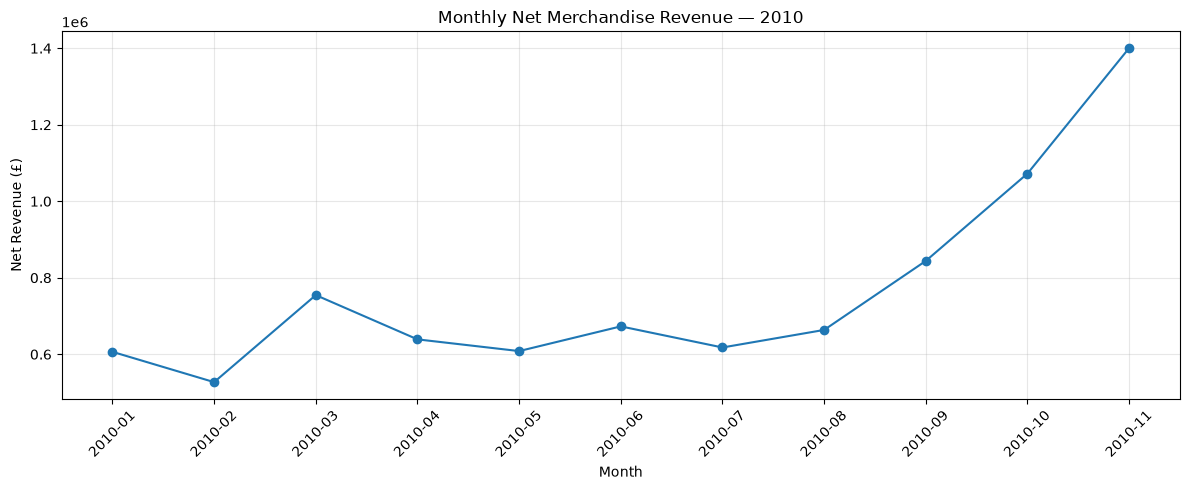

In [122]:
##### Visualise the monthly revenue trend
##### Now let's create your first Matplotlib line chart.

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_growth["Month"].astype(str),
    monthly_growth["NetRevenue"],
    marker="o"
)

plt.title("Monthly Net Merchandise Revenue — 2010")
plt.xlabel("Month")
plt.ylabel("Net Revenue (£)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Monthly Revenue Coverage and Comparability

I checked the first and last transaction dates for each month before comparing revenue performance.

The dataset contains only eight active transaction days in December 2010, with the final transaction recorded on 9 December. I therefore excluded December 2010 from the main month-over-month comparison to avoid interpreting incomplete data as a decline in sales.

I retained the December 2010 records in the original dataset and overall revenue calculations.

For the main monthly trend analysis, I focused on January to November 2010, while recognising that transaction activity alone does not establish complete operational coverage.

In [123]:
price_summary = df["Price"].describe()

display(price_summary)

count   525,461.00
mean          4.69
std         146.13
min     -53,594.36
25%           1.25
50%           2.10
75%           4.21
max      25,111.09
Name: Price, dtype: float64

In [124]:
cancellation_reconciliation = (
    df_classified.loc[
        df_classified["Invoice"]
        .astype("string")
        .str.upper()
        .str.startswith("C", na=False)
    ]
    .groupby("RevenueCategory", dropna=False)
    .agg(
        Records=("Invoice", "size"),
        SignedValue=("LineValue", "sum")
    )
    .sort_values("SignedValue")
)

display(cancellation_reconciliation)

print(
    "Total marked cancellation value:",
    f"£{cancellation_reconciliation['SignedValue'].sum():,.2f}"
)

,Records,SignedValue
RevenueCategory,,
Manual transaction,294,"-276,728.14"
Merchandise cancellation candidate,9582,"-247,831.81"
Marketplace fee,7,"-59,491.12"
Bank charges,42,"-28,756.23"
Discount,95,"-8,186.21"
Postage / delivery,110,"-3,616.90"
Samples / Review,40,"-3,090.21"
Accounting adjustment,31,"-2,062.69"
Gift voucher / Review,1,-69.56


Total marked cancellation value: £-629,855.37


In [125]:
test_cancellations = df_classified.loc[
    df_classified["Invoice"].astype("string")
    .str.upper()
    .str.startswith("C", na=False)
    & df_classified["RevenueCategory"].eq("Test transaction")
]

display(
    test_cancellations[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price", "LineValue"]
    ]
)

print("Records:", len(test_cancellations))
print("Signed value:", test_cancellations["LineValue"].sum())

,Invoice,StockCode,Description,Quantity,Price,LineValue
371777,C525272,TEST001,This is a test product.,-1,4.50,-4.50
371778,C525273,TEST001,This is a test product.,-1,4.50,-4.50
371779,C525274,TEST001,This is a test product.,-1,4.50,-4.50
371780,C525275,TEST001,This is a test product.,-2,4.50,-9.00


Records: 4
Signed value: -22.5


In [127]:
####Validate the reconciliation in Python

all_marked_cancellations = cancellation_reconciliation["SignedValue"].sum()

test_cancellation_value = test_cancellations["LineValue"].sum()

adjusted_cancellation_total = (
    all_marked_cancellations - test_cancellation_value
)

print(f"All marked cancellations: £{all_marked_cancellations:,.2f}")
print(f"Test cancellations: £{test_cancellation_value:,.2f}")
print(f"Excluding test cancellations: £{adjusted_cancellation_total:,.2f}")

assert abs(adjusted_cancellation_total - (-629832.87)) < 0.01

print("Cancellation reconciliation passed.")

All marked cancellations: £-629,855.37
Test cancellations: £-22.50
Excluding test cancellations: £-629,832.87
Cancellation reconciliation passed.


### Cancellation Reconciliation — Final Validation

I reconciled the cancellation transactions in the 2009–2010 Online Retail II dataset to understand the difference between total marked cancellations and merchandise-only cancellations.

The total signed value of all invoices beginning with **C** was **−£629,855.37**. However, I identified four cancellation records associated with the test-product code `TEST001`, with a combined value of **−£22.50**.

Excluding these test records produced a reconciled signed cancellation value of **−£629,832.87**, consistent with the earlier calculation.

Merchandise-only cancellations totalled **−£247,831.81**. The difference arises because marked cancellations also include manual transactions, marketplace fees, bank charges, discounts and other non-merchandise categories.

**Data quality decision:** I retained all original records for traceability but excluded confirmed test transactions and non-merchandise categories from merchandise cancellation KPIs.

The reconciliation passed the Python validation checks. These values represent signed transaction amounts rather than independently verified customer refunds.

In [128]:
#### Validate the revenue figures
print("PRELIMINARY MERCHANDISE REVENUE")

print(f"Gross sales: £{gross_sales:,.2f}")
print(f"Merchandise cancellations: £{cancellation_value:,.2f}")
print(f"Net revenue: £{net_merchandise_revenue:,.2f}")
print(f"Cancellation rate: {cancellation_rate:.2f}%")

assert abs(gross_sales + cancellation_value - net_merchandise_revenue) < 0.01

assert abs(
    monthly_revenue["NetRevenue"].sum()
    - net_merchandise_revenue
) < 0.01

print("Revenue validation passed.")

PRELIMINARY MERCHANDISE REVENUE
Gross sales: £9,838,748.95
Merchandise cancellations: £-247,831.81
Net revenue: £9,590,917.14
Cancellation rate: 2.52%
Revenue validation passed.
